# Topología Aplicada y Computacional

## Práctica 2

Para el desarrollo de esta practica se hará uso de los módulos `Simplex`, `SimplicialComplex` y `FilteredSimplicialComplex`, definidos en la anterior.

In [2]:
def power_set(elems: tuple[int, ...]) -> list[tuple[int, ...]]:
    """Return a list of all subsets as tuples."""
    n = len(elems)

    res = []

    for i in range(1, 1 << n):
        res.append(tuple(
            elems[j] for j in range(n) if i & (1 << j)
        ))

    return res

In [28]:
class Simplex:
    """Represents a simplex in topology, a set of vertices defining a geometric structure."""

    def __init__(self, vertices: tuple[int, ...]) -> None:
        """Initialize the Simplex object by providing the set of vertices."""

        # the vertices are sorted, so that the simplices (1,2,3) and (3,2,1) get the same representation
        verts = tuple(sorted(vertices))

        if len(set(verts)) != len(verts):
            raise ValueError("A simplex cannot contain repeated vertices")

        self._vertices: tuple[int, ...] = verts

    @property
    def vertices(self) -> tuple[int, ...]:
        """Return the sorted, immutable vertices of the simplex."""
        return self._vertices

    def dim(self) -> int:
        """Return the dimension of the simplex."""
        return len(self._vertices) - 1

    def is_face(self, other: Simplex) -> bool:
        """Return True if self is a face of the given simplex."""
        return set(self._vertices).issubset(other._vertices)

    def is_disjoint(self, other: Simplex) -> bool:
        """Return True if self and other share no common vertices."""
        return set(self._vertices).isdisjoint(other._vertices)

    def faces(self) -> set[Simplex]:
        """Return a set of all face simplices."""
        return {Simplex(t) for t in power_set(self._vertices)}

    def __iter__(self):
        """Return an iterator over vertices."""
        return iter(self._vertices)

    def __getitem__(self, index: int) -> int:
        """Return the vertex at the specified index."""
        return self._vertices[index]

    def __hash__(self) -> int:
        """Return the hash value for use in sets and dictionaries."""
        return hash(self._vertices)

    def __eq__(self, other: object) -> bool:
        """Return True if self and other represent the same vertices."""
        if isinstance(other, Simplex):
            return self._vertices == other._vertices

        return NotImplemented

    def __repr__(self) -> str:
        """Return a readable representation of the simplex."""
        return f"Simplex({self._vertices})"

In [29]:
class SimplicialComplex:
    """Represents a simplicial complex: a set of simplices closed under taking faces."""

    @staticmethod
    def _euler_characteristic(face_set: set[Simplex]) -> int:
        """Compute the Euler characteristic using face dimensions."""
        chi = 0

        for face in face_set:
            if face.dim() % 2 == 0:
                chi += 1
            else:
                chi -= 1

        return chi

    def __init__(self, generator: Iterable[Simplex]) -> None:
        """Initialize the simplicial complex with a set of simplices."""
        self.dim: int = -1
        self._face_set: set[Simplex] = set()

        for simplex in generator:
            faces = simplex.faces()

            self._face_set.update(faces)

            if simplex.dim() > self.dim:
                self.dim = simplex.dim()

        self.euler_characteristic: int = self._euler_characteristic(self.face_set)

    @property
    def face_set(self) -> set[Simplex]:
        """Return the set of all simplices (treat as read-only)."""
        return self._face_set

    def n_faces(self, dim: int) -> set[Simplex]:
        """Return all simplices with the specified dimension."""
        return {face for face in self.face_set if face.dim() == dim}

    def skeleton(self, dim: int) -> set[Simplex]:
        """Return all simplices with dimension less than or equal to the specified value."""
        return {face for face in self.face_set if face.dim() <= dim}

    def st(self, simplex: Simplex) -> set[Simplex]:
        """Return the star of the simplex."""
        res = {member for member in self.face_set if simplex.is_face(member)}

        if not res:
            raise ValueError("'simplex' is not a face")

        return res

    def closed_st(self, simplex: Simplex) -> SimplicialComplex:
        """Return the closed star of the simplex."""
        return SimplicialComplex(self.st(simplex))

    def lk(self, simplex: Simplex) -> set[Simplex]:
        """Return the link of the simplex."""
        closed = self.closed_st(simplex)
        return {elem for elem in closed.face_set if simplex.is_disjoint(elem)}

    def graph(self) -> dict[int, list[int]]:
        """Return a dictionary representing the 1-skeleton as a graph."""
        graph = defaultdict(list)

        for v1, v2 in self.n_faces(1):
            graph[v1].append(v2)
            graph[v2].append(v1)

        return graph

    def connected_components(self) -> int:
        """Return the number of connected components."""
        visited = set()

        graph = self.graph()
        vertices = [v[0] for v in self.n_faces(0)]

        components = 0

        for u in vertices:
            if u in visited:
                continue

            queue = [u]
            visited.add(u)

            while queue:
                v = queue.pop()

                for neig in graph[v]:
                    if neig not in visited:
                        queue.append(neig)
                        visited.add(neig)

            components += 1

        return components

    def insert(self, generator: Iterable[Simplex]) -> None:
        """Insert a generator of simplices into the complex."""
        additions = set()

        for simplex in generator:
            difference = simplex.faces() - self.face_set

            additions.update(difference)
            self._face_set.update(difference)

            if simplex.dim() > self.dim:
                self.dim = simplex.dim()

        self.euler_characteristic += self._euler_characteristic(additions)

In [36]:
from collections import defaultdict

class FilteredSimplicialComplex:
    """Represents a simplicial complex whose simplices carry filtration timestamps."""

    def _finish_insertion(self, additions: set[Simplex], time: float) -> None:
        """Add simplices to the timestamp dictionary."""
        if not additions:
            return

        self.timestamps[time].update(additions)

        for addition in additions:
            self.time_of[addition] = time

    def __init__(self, generator: Iterable[Simplex], time: float = 0.0) -> None:
        """Initialize the filtered complex with a set of simplices."""
        self.sc: SimplicialComplex = SimplicialComplex(generator)

        self.timestamps: dict[float, set[Simplex]] = defaultdict(set)
        self.time_of: dict[Simplex, float] = {}

        self._finish_insertion(self.sc.face_set, time)

    @property
    def face_set(self) -> set[Simplex]:
        """Return the face set."""
        return self.sc.face_set

    @property
    def filtration_order(self) -> list[Simplex]:
        """Return the filtration order as a sorted list of simplices."""
        return [
            simplex 
            for _, v in sorted(self.timestamps.items()) 
            for simplex in sorted(v, key=lambda s: (s.dim(), s.vertices))
        ]
    
    def insert(self, generator: Iterable[Simplex], time: float) -> None:
        """Insert a generator of simplices at the given timestamp."""
        generator = list(generator)

        for simplex in generator:
            if simplex in self.sc.face_set:
                raise ValueError("'generator' contains an already added simplex")

        additions: set[Simplex] = set()

        for simplex in generator:
            additions.update(simplex.faces())

        additions -= self.sc.face_set

        for addition in additions:
            for face in addition.faces():
                t = self.time_of.get(face)

                if t is not None and t > time:
                    raise ValueError("'generator' contains a face with a bad time value")

        self.sc.insert(generator)
        self._finish_insertion(additions, time)

    def filtration(self, time: float) -> SimplicialComplex:
        """Return the simplicial complex at the given timestamp."""
        return SimplicialComplex(
            simplex 
            for k, v in self.timestamps.items() 
            if k <= time 
            for simplex in v
        )

    def threshold(self, simplex: Simplex) -> Optional[float]:
        """Compute the threshold value of a simplex."""
        return self.time_of.get(simplex)

    def threshold_values(self) -> list[float]:
        """Return the sorted list of all threshold values."""
        return sorted(self.timestamps.keys())

**Ejercicio 1:** Definir una función que calcule la filtración de alfa complejos asociada a un conjunto de puntos en el plano. 

Primero se implementan 3 métodos auxiliares:

- `sq_distance` para calcular la distancia entre dos puntos al cuadrado.
- `circumradius` para calcular el circuncentro de tres puntos.
- `midpoint` para calcular el punto medio de dos puntos.

In [37]:
import math

def sq_distance(p: tuple[float, ...], q: tuple[float, ...]) -> float:
    """Return the squared Euclidean distance between two points."""
    if len(p) != len(q):
        raise ValueError("Points have different dimensions!")
    
    return sum((pk - qk)**2 for pk, qk in zip(p, q))

def circumradius(p: tuple[float, ...], q: tuple[float, ...], r: tuple[float, ...]) -> float:
    """Return the circumradius of the triangle through three points."""
    ax, ay = p[0] - r[0], p[1] - r[1]
    bx, by = q[0] - r[0], q[1] - r[1]

    cross = ax * by - ay * bx

    if cross == 0.0:
        raise ValueError("Points are collinear!")

    la  = math.hypot(ax, ay)
    lb  = math.hypot(bx, by)
    lab = math.hypot(ax - bx, ay - by)

    return la * lb * lab / (2.0 * abs(cross))

def midpoint(p: tuple[float, ...], q: tuple[float, ...]) -> tuple[float, ...]:
    """Return the midpoint between two points."""
    if len(p) != len(q):
        raise ValueError("Points have different dimensions!")

    return tuple((pi + qi) / 2 for pi, qi in zip(p, q))

Para realizar la función, además, se desarrolla la *factory class* `AlphaFiltration`, que se inicializa con la nube de puntos y produce el Alfa complejo con la función `AlphaFiltration.build`. Ésta, a su vez, hace uso de tres funciones auxiliares:

- `AlphaFiltration._circumradius` para calcular el circuncentro de tres puntos, dados sus índices en la nube.
- `AlphaFiltration._sq_dist` para calcular la distancia al cuadrado entre dos puntos, dados sus índices en la nube. Esta función, en vez de precomputar todas las distancias, las computa perezosamente, ya que solo se necesita saber las de un subconjunto de los puntos. 
- `AlphaFiltration._is_gabriel_edge` para comprobar en el algoritmo de construcción de Alpha complejos si una arista es del primer caso.

La función `AlphaFiltration.build` implementa el algoritmo de construcción con algunas modificaciones para evitar problemas con los números de coma flotante. El bucle principal recorre todos los triangulos hallados por la función `Delaunay` y computa el instante en el que aparece cada arista y triángulo. Para los triángulos simplemente se toma su circuncentro. Para las aristas el proceso es más complicado:

1. En el bucle principal se asume que están en el caso 1 y se les asigna un tiempo igual a su distancia entre 2. Al mismo tiempo se guarda en `incident_min` el mínimo circuncentro de los dos triángulos a los que pertenece la arista. Esto se hace porque en casos degenerados dónde 4 puntos pertenecen al mismo círculo, la función Delaunay escoge una triangulación aleatoria entre las dos posibles. En este caso aunque su circuncentro debería ser el mismo, un error de aproximación podría producir valores inválidos en la filtración final. Por ello se escoge el mínimo y se guarda.
2. Tras examinar los triángulos se recorren todas las aristas guardadas en `incident_min`. En teoría, lo único que habría que hacer sería comprobar si la arista pertenece al caso 2 y cambiar su valor al del circuncentro. Sin embargo, puede ocurrir otro fallo de aproximación. Si el circuncentro de dos puntos en un triángulo es la mitad que su distancia, podría ser que su circuncentro acabe con un valor menor a su distancia dividida entre 2. En tal caso hay que cambiar su valor al mínimo para evitar que la filtración se corrompa. 

Finalmente, una vez obtenido el instante de cada símplice, se construye añadiendo los símplices de menor dimensión primero.

In [38]:
from scipy.spatial import Delaunay

class AlphaFiltration:
    """Factory for building the Alpha complex filtration of a planar point cloud."""

    def __init__(self, points: list[tuple[float, ...]]) -> None:
        """Initialize the factory with a point cloud."""
        self._points: list[tuple[float, ...]] = points
        self._dist_map: dict[tuple[int, int], float] = {}
        self._n = len(points)

    def _circumradius(self, u: int, v: int, w: int) -> float:
        """Return the circumradius of the triangle through three vertices."""
        return circumradius(self._points[u], self._points[v], self._points[w])

    def _sq_dist(self, u: int, v: int) -> float:
        """Return the squared distance between two vertices, cached by index pair."""
        key = (u, v)

        if key not in self._dist_map:
            self._dist_map[key] = sq_distance(self._points[key[0]], self._points[key[1]])

        return self._dist_map[key]

    def _is_gabriel_edge(self, u: int, v: int, w: int) -> bool:
        """Return whether the edge is Gabriel with respect to the opposite vertex."""
        x, y, z = self._points[u], self._points[v], self._points[w]

        return 4 * sq_distance(midpoint(x, y), z) >= self._sq_dist(u, v)

    def build(self) -> FilteredSimplicialComplex:
        """Builds the alpha filtration of the point cloud."""
        triangle_map = {}
        edge_map = {}
        incident_min = {}
        not_gabriel = set()

        # Generate the Delaunay complex with sorted triangles
        delaunay = Delaunay(self._points)

        for simplex in delaunay.simplices:
            u, v, w = sorted(simplex)

            center = self._circumradius(u, v, w)

            # 1. The time of the triangle is it's circumradius
            triangle_map[(u, v, w)] = center

            # 2. The time of the edge has two cases
            for (a, b), opposite in (((u, v), w), ((u, w), v), ((v, w), u)):
                incident_min[(a, b)] = min(incident_min.get((a, b), math.inf), center)

                if self._is_gabriel_edge(a, b, opposite):
                    # 2b. Gabriel case: the time is the distance divided by 2
                    edge_map.setdefault((a, b), math.sqrt(self._sq_dist(a, b)) / 2)
                else:
                    not_gabriel.add((a, b))

        # 2a. Non-Gabriel case: the smallest circumradius among the incident triangles.
        for edge, smallest in incident_min.items():
            if edge in not_gabriel:
                edge_map[edge] = smallest
            else:
                edge_map[edge] = min(edge_map[edge], smallest)

        # Add the points
        sc = FilteredSimplicialComplex(Simplex((i,)) for i in range(self._n))

        # Add the edges
        for simpl, value in edge_map.items():
            sc.insert([Simplex(simpl)], value)

        # Add the triangles
        for simpl, value in triangle_map.items():
            sc.insert([Simplex(simpl)], value)

        return sc

**Ejercicio 2:** Definir una función que represente gráficamente dicho alfa complejo.

Basta con filtrar el alfa complejo según el flotante provisto y usar la interfaz de `matplotlib` y el método `voronoi_plot_2d` de `scipy` para dibujarlo.

In [42]:
import matplotlib.colors
import matplotlib.pyplot as plt

from scipy.spatial import Voronoi, voronoi_plot_2d

def alpha_plot_2d(points: list[tuple[float, ...]], fsc: FilteredSimplicialComplex, time: Optional[float] = None) -> None:
    """Plot the point cloud and the alpha complex at the given time."""
    if time is None:
        sc = fsc.sc
    else:
        sc = fsc.filtration(time)

    color = matplotlib.colors.ListedColormap("royalblue")
    voronoi = Voronoi(points)

    voronoi_plot_2d(voronoi, show_vertices=False, line_width=2, line_colors='red')

    for simplicial in sc.face_set:
        if simplicial.dim() == 0:
            u = points[simplicial[0]]
            plt.plot(u[0], u[1], 'ko')

        if simplicial.dim() == 1:
            u, v = points[simplicial[0]], points[simplicial[1]]
            plt.plot([u[0], v[0]], [u[1], v[1]], color='k', lw=2)

        if simplicial.dim() == 2:
            plt.tripcolor(
                [points[simplicial[i]][0] for i in range(3)],
                [points[simplicial[i]][1] for i in range(3)],
                [simplicial[i] for i in range(3)],
                edgecolor='k', lw=2, cmap=color
            )

    plt.show()

Se comprueba su funcionamiento con una nube de puntos:

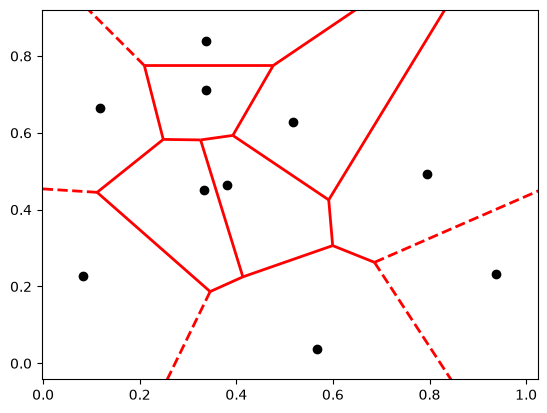

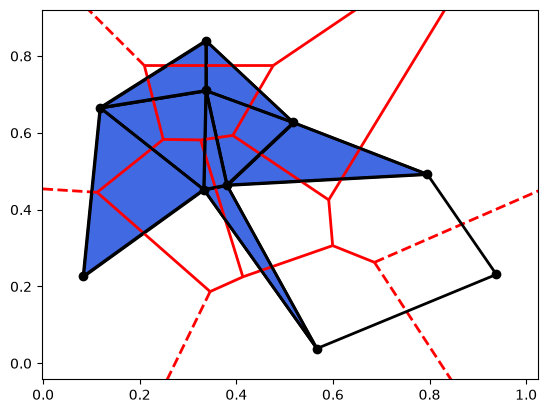

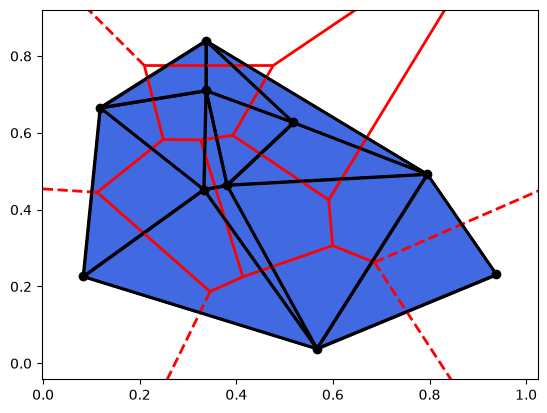

In [47]:
points = [(0.38021546727456423, 0.46419202339598786), (0.7951628297672293, 0.49263630135869474), 
          (0.566623772375203, 0.038325621649018426), (0.3369306814864865, 0.7103735061134965), 
          (0.08272837815822842, 0.2263273314352896), (0.5180166301873989, 0.6271769943824689), 
          (0.33691411899985035, 0.8402045183219995), (0.33244488399729255, 0.4524636520475205), 
          (0.11778991601260325, 0.6657734204021165), (0.9384303415747769, 0.2313873874340855)]

alpha = AlphaFiltration(points).build()

alpha_plot_2d(points, alpha, 0.00)
alpha_plot_2d(points, alpha, 0.25)
alpha_plot_2d(points, alpha, 1.00)

**Ejercicio 3:** Definir una función que calcule la filtración de complejos de Vietoris-Rips asociada a un conjunto de puntos.